In [1]:
import pandas as pd


In [2]:
df = pd.read_csv("loan_approval_1000.csv")

In [3]:
df

,Age,Income,Loan_Amount,Credit_Score,Employment_Type,Loan_Approved
0,59,77761.0,417505,337,Salaried,0
1,49,141178.0,328226,487,Salaried,0
2,35,56368.0,312805,356,Self-Employed,0
3,28,26783.0,218484,319,Salaried,0
4,41,131530.0,315064,572,Self-Employed,0
...,...,...,...,...,...,...
995,58,112447.0,259717,572,Unemployed,0
996,22,134994.0,314167,544,Unemployed,0
997,27,109899.0,169654,749,Salaried,1
998,38,40049.0,240868,546,Unemployed,0


In [6]:
df.isna().sum()

,0
Age,0
Income,50
Loan_Amount,0
Credit_Score,0
Employment_Type,50
Loan_Approved,0


In [8]:
len(df)

1000

In [21]:
mu = df["Income"].mean()
mod = df["Employment_Type"].mode()[0]

In [20]:
df["Employment_Type"].mode()

,Employment_Type
0,Salaried


In [23]:
df["Income"] = df["Income"].fillna(mu)
df["Employment_Type"] = df["Employment_Type"].fillna(mod)

In [24]:
df.isna().sum()

,0
Age,0
Income,0
Loan_Amount,0
Credit_Score,0
Employment_Type,0
Loan_Approved,0


In [25]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["Employment_Type"] = le.fit_transform(df["Employment_Type"])

In [26]:
df

,Age,Income,Loan_Amount,Credit_Score,Employment_Type,Loan_Approved
0,59,77761.0,417505,337,0,0
1,49,141178.0,328226,487,0,0
2,35,56368.0,312805,356,1,0
3,28,26783.0,218484,319,0,0
4,41,131530.0,315064,572,1,0
...,...,...,...,...,...,...
995,58,112447.0,259717,572,2,0
996,22,134994.0,314167,544,2,0
997,27,109899.0,169654,749,0,1
998,38,40049.0,240868,546,2,0


In [27]:
le.classes_

array(['Salaried', 'Self-Employed', 'Unemployed'], dtype=object)

In [28]:
from sklearn.model_selection import train_test_split

X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((800, 5), (200, 5))

In [37]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [38]:
y_pred = lr.predict(X_test)

In [39]:
y_pred

array([1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1])

In [40]:
y_test

,Loan_Approved
521,1
737,0
740,0
660,1
411,1
...,...
408,1
332,1
208,0
613,0


In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       135
           1       0.70      0.62      0.66        65

    accuracy                           0.79       200
   macro avg       0.76      0.74      0.75       200
weighted avg       0.79      0.79      0.79       200



In [45]:
from sklearn.metrics import confusion_matrix

In [47]:
import matplotlib.pyplot as plt

In [49]:
import seaborn as sns

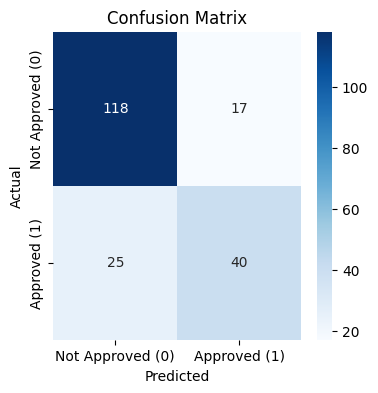

In [50]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Approved (0)", "Approved (1)"],
    yticklabels=["Not Approved (0)", "Approved (1)"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()